# Pipeline completo de clasificación MNIST con TensorFlow/Keras


## Objetivos

1. Cargar MNIST con `tensorflow_datasets`.
2. Dividir los datos en **train / validation / test**.
3. Construir el pipeline con `tf.data`:
   - `map`
   - `cache`
   - `shuffle`
   - `batch`
   - `prefetch`
4. Normalizar los píxeles.
5. Calcular **pesos de clase** a partir del conjunto de entrenamiento.
6. Construir una red neuronal únicamente con capas densas, añadiendo `BatchNormalization`.
7. Usar `compile()` y `fit()`.
8. Utilizar callbacks:
   - TensorBoard
   - EarlyStopping
   - ModelCheckpoint
   - ReduceLROnPlateau
9. Inspeccionar `History`.
10. Cargar el mejor modelo.
11. Evaluar sobre test.
12. Generar predicciones, matriz de confusión y ejemplos visuales.

> MNIST es un dataset aproximadamente balanceado. Aun así calcularemos pesos inversamente proporcionales a la frecuencia de cada clase para mostrar el mecanismo correcto de `class_weight`.

In [1]:
# Si fuera necesario:
# !pip install tensorflow tensorflow-datasets

from pathlib import Path
from datetime import datetime

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds

print("TensorFlow:", tf.__version__)

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

TensorFlow: 2.21.0


# 1. Carga de MNIST

Usamos `tensorflow_datasets` porque entrega directamente objetos compatibles con `tf.data.Dataset`.

La división se realiza desde el inicio:

- 40% de `train` → entrenamiento
- 10% de `train` → validación
- `test` original → test final

El conjunto test **no participa** en la selección del modelo.

In [2]:
(ds_train_raw, ds_val_raw, ds_test_raw), ds_info = tfds.load(
    name="mnist",
    split=[
        "train[:40%]",
        "train[40%:50%]",
        "test[:50%]"
    ],
    shuffle_files=True,
    as_supervised=True,
    with_info=True
)

NUM_CLASSES = ds_info.features["label"].num_classes
CLASS_NAMES = [str(i) for i in range(NUM_CLASSES)]

print(ds_info)
print("Número de clases:", NUM_CLASSES)

tfds.core.DatasetInfo(
    name='mnist',
    full_name='mnist/3.0.1',
    description="""
    The MNIST database of handwritten digits.
    """,
    homepage='http://yann.lecun.com/exdb/mnist/',
    data_dir='C:\\Users\\javier\\tensorflow_datasets\\mnist\\3.0.1',
    file_format=tfrecord,
    download_size=11.06 MiB,
    dataset_size=21.00 MiB,
    features=FeaturesDict({
        'image': Image(shape=(28, 28, 1), dtype=uint8),
        'label': ClassLabel(shape=(), dtype=int64, num_classes=10),
    }),
    supervised_keys=('image', 'label'),
    disable_shuffling=False,
    nondeterministic_order=False,
    splits={
        'test': <SplitInfo num_examples=10000, num_shards=1>,
        'train': <SplitInfo num_examples=60000, num_shards=1>,
    },
    citation="""@article{lecun2010mnist,
      title={MNIST handwritten digit database},
      author={LeCun, Yann and Cortes, Corinna and Burges, CJ},
      journal={ATT Labs [Online]. Available: http://yann.lecun.com/exdb/mnist},
      volume=

# 2. Exploración de los datos

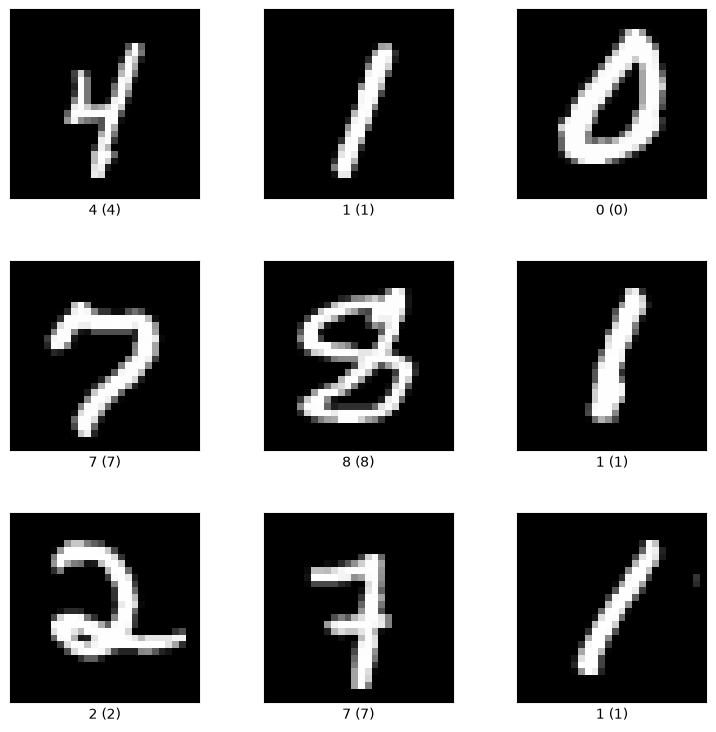

In [3]:
fig = tfds.show_examples(ds_train_raw, ds_info)

In [4]:
for image, label in ds_train_raw.take(1):
    print("Image shape:", image.shape)
    print("Image dtype:", image.dtype)
    print("Label:", label.numpy())
    print("Pixel min/max:", tf.reduce_min(image).numpy(), tf.reduce_max(image).numpy())

Image shape: (28, 28, 1)
Image dtype: <dtype: 'uint8'>
Label: 4
Pixel min/max: 0 255


# 3. Pesos de clase

Calculamos la frecuencia de cada clase **solo con train**.

Usaremos:

$
w_c = \frac{N}{K\,n_c}
$

donde:

- \(N\): número total de ejemplos de entrenamiento.
- \(K\): número de clases.
- \(n_c\): número de ejemplos de la clase \(c\).

Una clase menos frecuente obtiene un peso mayor.

In [5]:
class_counts = np.zeros(NUM_CLASSES, dtype=np.int64)

for _, label in tfds.as_numpy(ds_train_raw):
    class_counts[label] += 1

n_train = class_counts.sum()

class_weight = {
    class_id: float(n_train / (NUM_CLASSES * count))
    for class_id, count in enumerate(class_counts)
}

print("Frecuencias:")
for class_id, count in enumerate(class_counts):
    print(
        f"Clase {class_id}: n={count:5d} "
        f"peso={class_weight[class_id]:.4f}"
    )

Frecuencias:
Clase 0: n= 2416 peso=0.9934
Clase 1: n= 2691 peso=0.8919
Clase 2: n= 2388 peso=1.0050
Clase 3: n= 2389 peso=1.0046
Clase 4: n= 2355 peso=1.0191
Clase 5: n= 2160 peso=1.1111
Clase 6: n= 2370 peso=1.0127
Clase 7: n= 2496 peso=0.9615
Clase 8: n= 2331 peso=1.0296
Clase 9: n= 2404 peso=0.9983


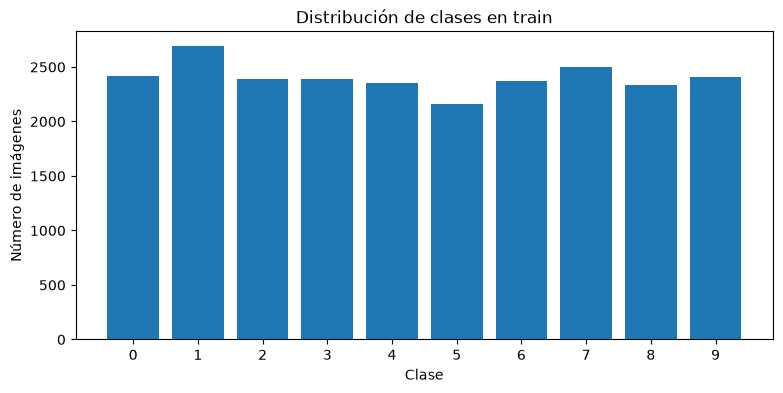

In [6]:
plt.figure(figsize=(9, 4))
plt.bar(np.arange(NUM_CLASSES), class_counts)
plt.xticks(np.arange(NUM_CLASSES))
plt.xlabel("Clase")
plt.ylabel("Número de imágenes")
plt.title("Distribución de clases en train")
plt.show()

# 4. Preprocesamiento con `tf.data`

El pipeline sigue el patrón:

```text
Dataset
   ↓
map(preprocess)
   ↓
cache()
   ↓
shuffle()       # solo train
   ↓
batch()
   ↓
prefetch(AUTOTUNE)
```

La normalización transforma los píxeles de `[0,255]` a `[0,1]`.

La imagen se conserva como `(28, 28, 1)` y se aplana posteriormente dentro del modelo.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE
BATCH_SIZE = 128
SHUFFLE_BUFFER = 10_000


def preprocess_mnist_train(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    image = tf.image.random_brightness(
        image,
        max_delta=0.10
    )
    image= tf.image.random_flip_left_right(image)
    image = tf.clip_by_value(image,0.0,1.0)
    label = tf.one_hot(label,depth=NUM_CLASSES)
    return image, label

def preprocess_eval_test(image, label):
    image = tf.cast(image, tf.float32) / 255.0
    label = tf.one_hot(label,depth=NUM_CLASSES)
    return image, label



def build_dataset(dataset,preprocess_mnist=preprocess_eval_test, training=False):
    dataset = dataset.map(preprocess_mnist,num_parallel_calls=AUTOTUNE)
    if training:
        dataset = dataset.shuffle(
            SHUFFLE_BUFFER,
            seed=SEED,
            reshuffle_each_iteration=True)
    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(AUTOTUNE)
    return dataset

train_ds = build_dataset(ds_train_raw,preprocess_mnist=preprocess_mnist_train, training=True)
val_ds = build_dataset(ds_val_raw, preprocess_mnist=preprocess_eval_test, training=False)
test_ds = build_dataset(ds_test_raw, preprocess_mnist=preprocess_eval_test, training=False)

## Inspeccionar un batch

Antes de entrenar conviene comprobar:

- forma;
- tipo;
- rango;
- labels.

In [8]:
for images_batch, labels_batch in train_ds.take(1):
    print(images_batch.shape, labels_batch.shape)
    

(128, 28, 28, 1) (128, 10)


In [11]:
labels_batch[:5]

<tf.Tensor: shape=(5, 10), dtype=float32, numpy=
array([[0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 1., 0., 0., 0., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.],
       [0., 0., 0., 0., 0., 0., 0., 1., 0., 0.],
       [0., 0., 0., 0., 1., 0., 0., 0., 0., 0.]], dtype=float32)>

# 5. Modelo denso

Usamos únicamente capas densas para el aprendizaje:

```text
28×28×1
   ↓
Flatten
   ↓
Dense
   ↓
BatchNormalization
   ↓
ReLU
   ↓
Dropout
   ↓
Dense
   ↓
BatchNormalization
   ↓
ReLU
   ↓
Dropout
   ↓
Dense(10)
```

La última capa entrega **logits**. Por ello la función de pérdida se configurará con `from_logits=True`.

In [12]:
tf.keras.backend.clear_session()

model = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),

    tf.keras.layers.Flatten(),

    tf.keras.layers.Dense(
        128,
        use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(
        64,
        use_bias=False
    ),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation("relu"),
    tf.keras.layers.Dropout(0.20),

    tf.keras.layers.Dense(NUM_CLASSES)
])

model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,962 (429.54 KB)

 Trainable params: 109,578 (428.04 KB)

 Non-trainable params: 384 (1.50 KB)

# 6. `compile()`

`compile()` configura el entrenamiento.

Usaremos:

- **Adam** como optimizador.
- **SparseCategoricalCrossentropy** porque los labels son enteros `0...9`.
- `from_logits=True` porque no añadimos `Softmax` dentro del modelo.
- `SparseCategoricalAccuracy` como métrica.

In [14]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=1e-3
    ),

    loss=tf.keras.losses.CategoricalCrossentropy(
        from_logits=True
    ),

    metrics=[
        tf.keras.metrics.CategoricalAccuracy(
            name="accuracy"
        ),
        tf.keras.metrics.F1Score(
        average="macro",
        name="f1_macro"
    )
    ]
)

# 7. Callbacks

Los callbacks permiten automatizar acciones durante `fit()`.

Usaremos:

### `TensorBoard`
Registra loss, métricas y otra información.

### `EarlyStopping`
Detiene el entrenamiento cuando `val_loss` deja de mejorar.

### `ModelCheckpoint`
Guarda únicamente el mejor modelo.

### `ReduceLROnPlateau`
Reduce el learning rate cuando `val_loss` se estabiliza.

In [15]:
ARTIFACT_DIR = Path("mnist_artifacts")
ARTIFACT_DIR.mkdir(exist_ok=True)

timestamp = datetime.now().strftime("%Y%m%d-%H%M%S")
log_dir = ARTIFACT_DIR / "logs" / timestamp

best_model_path = ARTIFACT_DIR / "best_mnist.keras"

callbacks = [
    tf.keras.callbacks.TensorBoard(
        log_dir=str(log_dir),
        histogram_freq=1,
        update_freq="epoch"
    ),

    tf.keras.callbacks.EarlyStopping(
        monitor="val_loss",
        mode="min",
        patience=4,
        restore_best_weights=True,
        verbose=1
    ),

    tf.keras.callbacks.ModelCheckpoint(
        filepath=str(best_model_path),
        monitor="val_loss",
        mode="min",
        save_best_only=True,
        verbose=1
    ),

    tf.keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        mode="min",
        factor=0.5,
        patience=2,
        min_lr=1e-6,
        verbose=1
    ),

    tf.keras.callbacks.TerminateOnNaN()
]

# 8. Entrenamiento con `fit()`

El argumento `class_weight` aplica los pesos calculados anteriormente a la función de pérdida.

Keras determina el peso correspondiente a partir del label de cada muestra.

In [16]:
EPOCHS = 30

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
    class_weight=class_weight,
    verbose=1
)

Epoch 1/30


c:\Users\javier\Documents\deep_learning_2026_phd\deep-learning-i\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


187/188 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7468 - f1_macro: 0.7421 - loss: 0.8470
Epoch 1: val_loss improved from None to 0.48657, saving model to mnist_artifacts\best_mnist.keras

Epoch 1: finished saving model to mnist_artifacts\best_mnist.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 4s 8ms/step - accuracy: 0.7471 - f1_macro: 0.7424 - loss: 0.8458 - val_accuracy: 0.8752 - val_f1_macro: 0.8726 - val_loss: 0.4866 - learning_rate: 0.0010
Epoch 2/30
181/188 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8673 - f1_macro: 0.8647 - loss: 0.4444
Epoch 2: val_loss improved from 0.48657 to 0.32386, saving model to mnist_artifacts\best_mnist.keras

Epoch 2: finished saving model to mnist_artifacts\best_mnist.keras
188/188 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8673 - f1_macro: 0.8647 - loss: 0.4436 - val_accuracy: 0.9012 - val_f1_macro: 0.9002 - val_loss: 0.3239 - learning_rate: 0.0010
Epoch 3/30
178/188 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8961 - f1_macro: 0.8944 - loss: 0.

# 9. TensorBoard

En Jupyter/Colab:

In [ ]:
# Ejecutar después de entrenar:
# %load_ext tensorboard
# %tensorboard --logdir mnist_artifacts/logs

# 10. `History`

`fit()` devuelve un objeto `History`. El atributo `history.history` contiene una lista por época para cada métrica registrada.

In [17]:
print(history.history.keys())
print("Épocas ejecutadas:", len(history.epoch))

dict_keys(['accuracy', 'f1_macro', 'loss', 'val_accuracy', 'val_f1_macro', 'val_loss', 'learning_rate'])
Épocas ejecutadas: 20


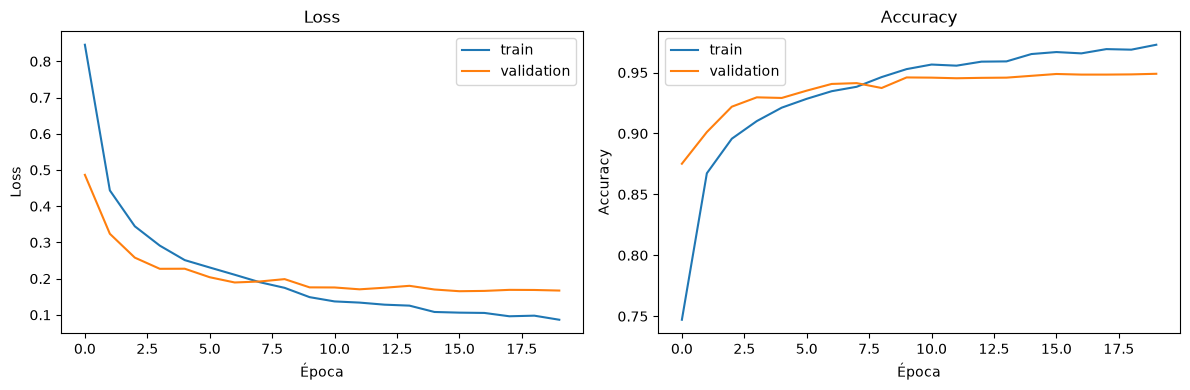

In [18]:
fig = plt.figure(figsize=(12, 4))

ax1 = fig.add_subplot(1, 2, 1)
ax1.plot(history.history["loss"], label="train")
ax1.plot(history.history["val_loss"], label="validation")
ax1.set_xlabel("Época")
ax1.set_ylabel("Loss")
ax1.set_title("Loss")
ax1.legend()

ax2 = fig.add_subplot(1, 2, 2)
ax2.plot(history.history["accuracy"], label="train")
ax2.plot(history.history["val_accuracy"], label="validation")
ax2.set_xlabel("Época")
ax2.set_ylabel("Accuracy")
ax2.set_title("Accuracy")
ax2.legend()

plt.tight_layout()
plt.show()

# 11. Cargar el mejor modelo

Aunque `EarlyStopping(restore_best_weights=True)` restaura los mejores pesos en el objeto actual, para un pipeline reproducible cargamos explícitamente el checkpoint guardado.

In [19]:
best_model = tf.keras.models.load_model(best_model_path)
best_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,192 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 329,120 (1.26 MB)

 Trainable params: 109,578 (428.04 KB)

 Non-trainable params: 384 (1.50 KB)

 Optimizer params: 219,158 (856.09 KB)

# 12. Evaluación final sobre test

El conjunto test se utiliza ahora por primera vez como evaluación final.

In [20]:
test_metrics = best_model.evaluate(
    test_ds,
    return_dict=True,
    verbose=1)
print(test_metrics)

40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9532 - f1_macro: 0.9527 - loss: 0.1488 
{'accuracy': 0.9531999826431274, 'f1_macro': 0.9526874423027039, 'loss': 0.14882299304008484}


# 13. Predicción

El modelo produce logits. Para convertirlos en probabilidades aplicamos `softmax`.

In [21]:
images_test, labels_test = next(iter(test_ds))

logits = best_model.predict(
    images_test,verbose=0)

probabilities = tf.nn.softmax(logits, axis=1)
predicted_classes = tf.argmax(
    probabilities,
    axis=1,
    output_type=tf.int64
)

print("Probabilities shape:", probabilities.shape)
print("Predicciones:", predicted_classes[:15].numpy())
print("Reales:      ", labels_test[:15].numpy())

Probabilities shape: (128, 10)
Predicciones: [2 0 4 8 7 6 0 6 3 1 8 0 7 9 8]
Reales:       [[0. 0. 1. 0. 0. 0. 0. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0.]
 [0. 0. 0. 1. 0. 0. 0. 0. 0. 0.]
 [0. 1. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]
 [1. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 1. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 1.]
 [0. 0. 0. 0. 0. 0. 0. 0. 1. 0.]]


In [28]:
probabilities[7]

<tf.Tensor: shape=(10,), dtype=float32, numpy=
array([2.1886282e-05, 1.4509949e-06, 1.5359915e-04, 3.0590989e-05,
       6.3701755e-06, 1.2423007e-03, 9.9269015e-01, 1.0661430e-06,
       5.8521209e-03, 5.2522785e-07], dtype=float32)>

# 14. Visualizar predicciones

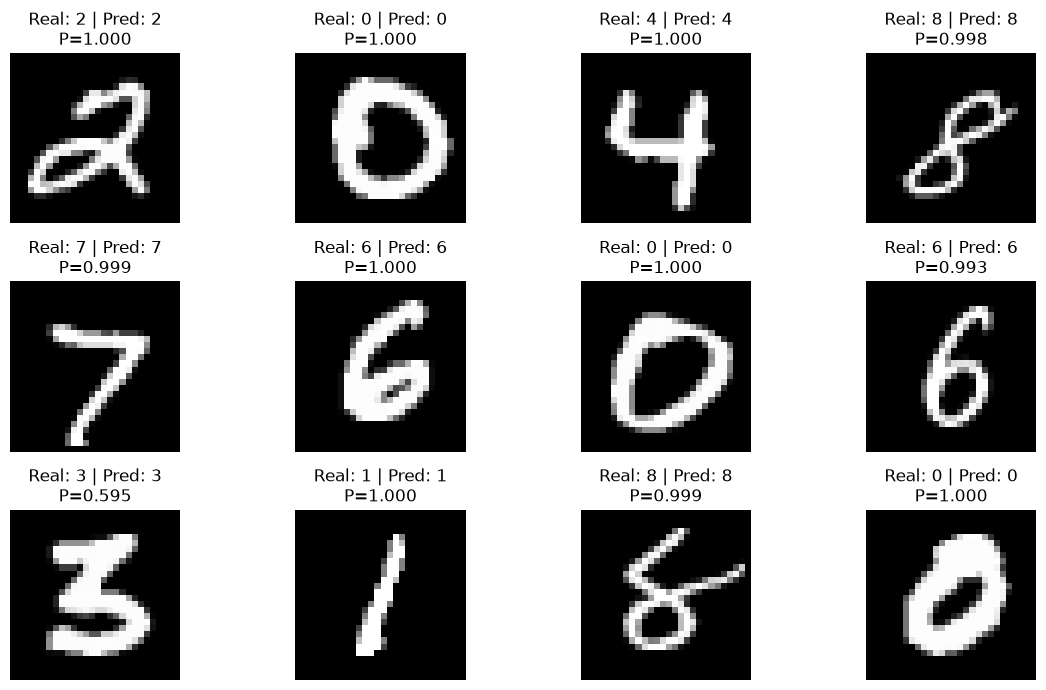

In [24]:
plt.figure(figsize=(12, 7))

for i in range(12):
    plt.subplot(3, 4, i + 1)

    plt.imshow(
        images_test[i].numpy().squeeze(),
        cmap="gray"
    )

    pred = int(predicted_classes[i])
    true = int(tf.argmax(labels_test[i]))
    confidence = float(tf.reduce_max(probabilities[i]))

    plt.title(
        f"Real: {true} | Pred: {pred}\n"
        f"P={confidence:.3f}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

# 15. Predicción sobre todo test y matriz de confusión

In [29]:
all_true = []
all_pred = []

for images, labels in test_ds:
    logits = best_model(images, training=False)
    preds = tf.argmax(
        logits,
        axis=1,
        output_type=tf.int64
    )
    true_labels = tf.argmax(
        labels,
        axis=1,
        output_type=tf.int64
    )

    all_true.append(true_labels.numpy())
    all_pred.append(preds.numpy())

all_true = np.concatenate(all_true)
all_pred = np.concatenate(all_pred)

confusion_matrix = tf.math.confusion_matrix(
    all_true,
    all_pred,
    num_classes=NUM_CLASSES
).numpy()

print(confusion_matrix)

[[492   0   0   0   0   0   3   3   2   1]
 [  0 551   3   0   0   0   0   0   4   0]
 [  5   0 514   4   2   3   7   2   8   0]
 [  0   1   5 471   0  15   0   4   6   0]
 [  0   0   2   0 444   0   6   2   0   9]
 [  2   2   4   9   1 417   3   8   5   3]
 [  5   1   4   0   3   7 463   1   1   0]
 [  0   7   7   4   0   1   0 486   1  13]
 [  1   0   1   7   2   4   1   2 479   3]
 [  3   1   0   3   7   0   0   7   3 449]]


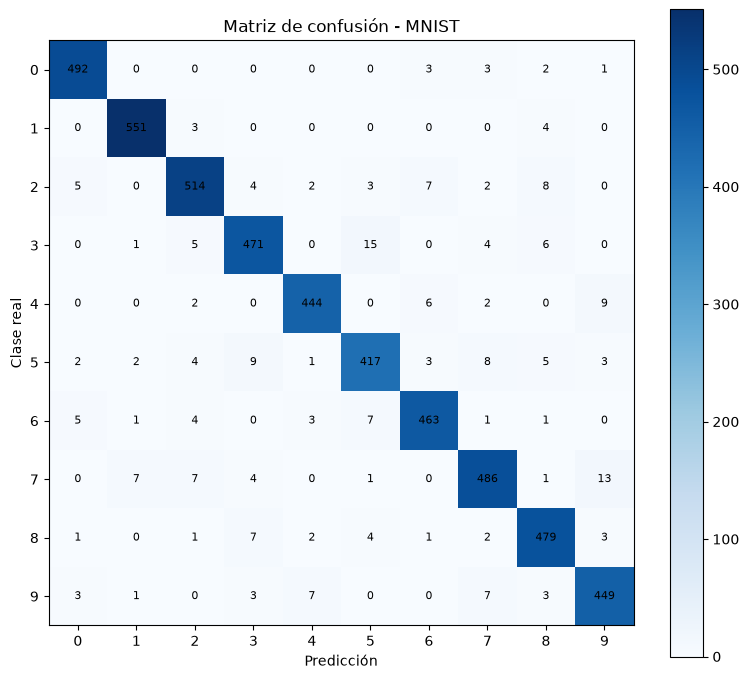

In [30]:
plt.figure(figsize=(8, 7))
plt.imshow(confusion_matrix, cmap="Blues")
plt.colorbar()

plt.xticks(range(NUM_CLASSES))
plt.yticks(range(NUM_CLASSES))

plt.xlabel("Predicción")
plt.ylabel("Clase real")
plt.title("Matriz de confusión - MNIST")

for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        plt.text(
            j,
            i,
            confusion_matrix[i, j],
            ha="center",
            va="center",
            fontsize=8
        )

plt.tight_layout()
plt.show()

# 16. Guardar un modelo final

El checkpoint ya guardó el mejor modelo. También podemos guardar explícitamente el modelo cargado:

In [31]:
final_path = ARTIFACT_DIR / "mnist_final.keras"
best_model.save(final_path)

print("Modelo guardado en:", final_path)

Modelo guardado en: mnist_artifacts\mnist_final.keras


# Resumen del pipeline

```text
tensorflow_datasets
        ↓
train / validation / test
        ↓
map(normalización)
        ↓
cache
        ↓
shuffle (train)
        ↓
batch
        ↓
prefetch
        ↓
MLP + BatchNormalization
        ↓
compile
        ↓
fit + class_weight
        ↓
TensorBoard
EarlyStopping
ModelCheckpoint
ReduceLROnPlateau
        ↓
load_model(best checkpoint)
        ↓
evaluate(test)
        ↓
predict
        ↓
matriz de confusión / visualización
```